## В этом домашнем задании вы сделаете первые шаги в мире линейной бинарной классификации!

In [1]:
import pandas as pd
import numpy as np
import warnings

#### Задание 1

Мы будем работать с данными **Microsoft Malware Detection**

Таргетом будет последний столбец `HasDetection`, который принимает значения $\{0,\, 1\}$ в случае отсутствия или наличия вируса на компьютере соответственно. Признаками будут выступать всевозможные характеристики компьютера.

In [2]:
data = pd.read_csv('train.csv')

C:\Users\Max\AppData\Local\Temp\ipykernel_6720\2815211952.py:1: DtypeWarning: Columns (28) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('train.csv')


In [3]:
data.head()

,MachineIdentifier,ProductName,EngineVersion,AppVersion,AvSigVersion,IsBeta,RtpStateBitfield,IsSxsPassiveMode,DefaultBrowsersIdentifier,AVProductStatesIdentifier,...,Census_FirmwareVersionIdentifier,Census_IsSecureBootEnabled,Census_IsWIMBootEnabled,Census_IsVirtualDevice,Census_IsTouchEnabled,Census_IsPenCapable,Census_IsAlwaysOnAlwaysConnectedCapable,Wdft_IsGamer,Wdft_RegionIdentifier,HasDetections
0,0000028988387b115f69f31a3bf04f09,win8defender,1.1.15100.1,4.18.1807.18075,1.273.1735.0,0,7.0,0,NaN,53447.0,...,36144.0,0,NaN,0.0,0,0,0.0,0.0,10.0,0
1,000007535c3f730efa9ea0b7ef1bd645,win8defender,1.1.14600.4,4.13.17134.1,1.263.48.0,0,7.0,0,NaN,53447.0,...,57858.0,0,NaN,0.0,0,0,0.0,0.0,8.0,0
2,000007905a28d863f6d0d597892cd692,win8defender,1.1.15100.1,4.18.1807.18075,1.273.1341.0,0,7.0,0,NaN,53447.0,...,52682.0,0,NaN,0.0,0,0,0.0,0.0,3.0,0
3,00000b11598a75ea8ba1beea8459149f,win8defender,1.1.15100.1,4.18.1807.18075,1.273.1527.0,0,7.0,0,NaN,53447.0,...,20050.0,0,NaN,0.0,0,0,0.0,0.0,3.0,1
4,000014a5f00daa18e76b81417eeb99fc,win8defender,1.1.15100.1,4.18.1807.18075,1.273.1379.0,0,7.0,0,NaN,53447.0,...,19844.0,0,0.0,0.0,0,0,0.0,0.0,1.0,1


Удалите константные признаки и признаки `ProductName` `MachineIdentifier`

In [4]:
### Your code is here
data = data.drop(['MachineIdentifier','ProductName'], axis=1)

data = data.loc[:, data.nunique() > 1]


In [5]:
num_cols = data.select_dtypes(include=['number']).columns
data[num_cols].corr()

,RtpStateBitfield,IsSxsPassiveMode,DefaultBrowsersIdentifier,AVProductStatesIdentifier,AVProductsInstalled,AVProductsEnabled,HasTpm,CountryIdentifier,CityIdentifier,OrganizationIdentifier,...,Census_FirmwareManufacturerIdentifier,Census_FirmwareVersionIdentifier,Census_IsSecureBootEnabled,Census_IsVirtualDevice,Census_IsTouchEnabled,Census_IsPenCapable,Census_IsAlwaysOnAlwaysConnectedCapable,Wdft_IsGamer,Wdft_RegionIdentifier,HasDetections
RtpStateBitfield,1.000000,-0.887801,-0.019034,0.116112,-0.186467,0.001476,-0.003062,0.012002,-0.005105,0.005531,...,0.006933,0.005887,-0.014768,0.008368,0.011010,0.008522,0.020974,-0.024006,-0.003294,0.040301
IsSxsPassiveMode,-0.887801,1.000000,0.015305,-0.119759,0.195747,0.028794,0.013678,-0.013174,0.005309,-0.004792,...,-0.008146,-0.005039,0.020073,-0.009247,-0.006853,-0.004118,-0.016492,0.027829,0.004408,-0.033334
DefaultBrowsersIdentifier,-0.019034,0.015305,1.000000,0.018942,-0.008490,-0.012924,-0.022798,-0.002922,0.020125,0.008576,...,0.009226,0.023396,0.071890,0.011094,0.005479,0.001377,0.011655,-0.015069,0.019196,0.000550
AVProductStatesIdentifier,0.116112,-0.119759,0.018942,1.000000,-0.633143,-0.121284,0.141211,0.006177,-0.003061,0.011922,...,-0.014145,-0.017295,-0.030891,0.027611,0.042399,0.036849,0.062681,-0.022031,-0.022521,0.117886
AVProductsInstalled,-0.186467,0.195747,-0.008490,-0.633143,1.000000,0.286555,0.025515,-0.024188,0.002176,-0.015581,...,0.060172,0.042227,0.215085,-0.044611,-0.012675,-0.029135,-0.067930,0.012911,0.034657,-0.150388
AVProductsEnabled,0.001476,0.028794,-0.012924,-0.121284,0.286555,1.000000,-0.042454,-0.020833,0.005584,-0.007070,...,0.015292,0.001993,0.039253,-0.010971,0.000251,-0.008006,-0.018205,-0.013496,0.005939,-0.040548
HasTpm,-0.003062,0.013678,-0.022798,0.141211,0.025515,-0.042454,1.000000,0.005445,-0.008020,0.001395,...,-0.003174,0.004215,0.084817,0.001247,0.026977,0.017876,0.026833,0.064512,-0.015499,0.003874
CountryIdentifier,0.012002,-0.013174,-0.002922,0.006177,-0.024188,-0.020833,0.005445,1.000000,0.001265,0.041266,...,-0.016986,0.019472,-0.009025,-0.005176,0.000522,-0.011608,-0.003541,0.019560,-0.116526,0.006380
CityIdentifier,-0.005105,0.005309,0.020125,-0.003061,0.002176,0.005584,-0.008020,0.001265,1.000000,-0.034749,...,-0.025524,0.014218,0.013022,0.002143,-0.012647,0.000417,-0.001863,0.004348,-0.058086,-0.004438
OrganizationIdentifier,0.005531,-0.004792,0.008576,0.011922,-0.015581,-0.007070,0.001395,0.041266,-0.034749,1.000000,...,0.011900,0.009327,0.004239,0.003134,0.006647,0.002904,0.001717,-0.004104,0.017932,0.008471


<Axes: >

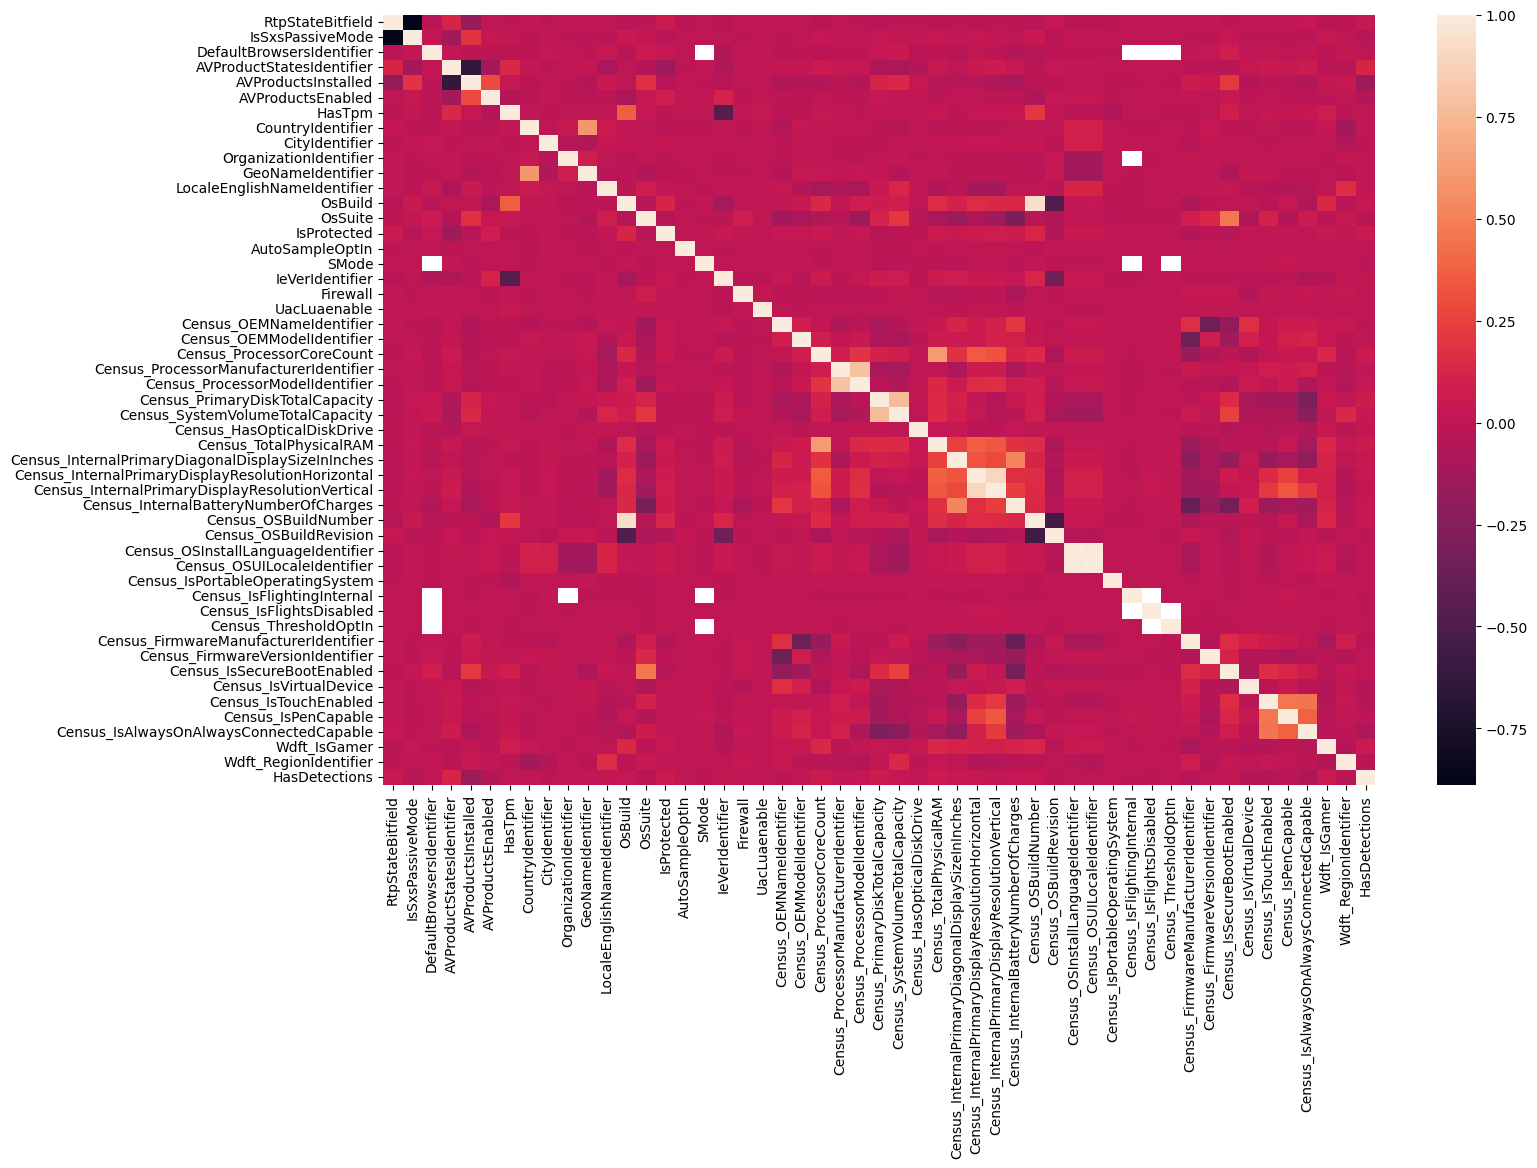

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
fig =plt.figure()
fig.set_size_inches(16, 10)

sns.heatmap(data[num_cols].corr())

In [7]:
def get_redundant_pairs(df):
    '''Получить диагональные и нижние треугольные пары матрицы корреляции'''
    pairs_to_drop = set()
    cols = df.columns
    for i in range(0, df.shape[1]):
        for j in range(0, i + 1):
            pairs_to_drop.add((cols[i], cols[j]))
    return pairs_to_drop

def get_top_abs_correlations(df, n=5):
    # Вычисляем матрицу корреляции по модулю
    au_corr = df.corr().abs().unstack()
    # Находим избыточные пары (диагональ и одну из половин матрицы)
    labels_to_drop = get_redundant_pairs(df)
    # Удаляем их и сортируем по убыванию
    au_corr = au_corr.drop(labels=labels_to_drop).sort_values(ascending=False)
    return au_corr[0:n]

print(get_top_abs_correlations(data[num_cols], 10))

Census_OSInstallLanguageIdentifier                 Census_OSUILocaleIdentifier                        0.988034
OsBuild                                            Census_OSBuildNumber                               0.937643
Census_InternalPrimaryDisplayResolutionHorizontal  Census_InternalPrimaryDisplayResolutionVertical    0.901740
RtpStateBitfield                                   IsSxsPassiveMode                                   0.887801
Census_ProcessorManufacturerIdentifier             Census_ProcessorModelIdentifier                    0.799299
Census_PrimaryDiskTotalCapacity                    Census_SystemVolumeTotalCapacity                   0.769232
AVProductStatesIdentifier                          AVProductsInstalled                                0.633143
Census_ProcessorCoreCount                          Census_TotalPhysicalRAM                            0.611502
CountryIdentifier                                  GeoNameIdentifier                                  0.595889
C

In [8]:
# data = data[num_cols].drop(['Census_OSInstallLanguageIdentifier','OsBuild','Census_InternalPrimaryDisplayResolutionHorizontal'], axis=1)
# get_top_abs_correlations(data, 10)

Посмотрите на соотношение классов в таргете. Все ли хорошо?

In [9]:
print(sum(data['HasDetections'] == 1), '- positive class,')
print(sum(data['HasDetections'] == 0), '- negative class')

100060 - positive class,
99940 - negative class


In [1]:
data.isna().sum()

NameError: name 'data' is not defined

Ответьте на вопрос: почему с вашей точки зрения важно иметь представление о балансе классов в ваших данных?

Избавьтесь от пропусков в данных! 

Новый для нас прием: признаки с более чем половиной пропусков следует удалить.

Согласитесь, если в вашей колонке среди 100 объектов всего лишь у 2 есть какое-то непропущенное значение, странно все остальные заполнять средним от этих двух чисел. Такие "редкие" признаки лучше вообще опустить!


В категориальных колонках заменим отсутствующую категорию просто некоторой новой и назовем ее `NaN`.

А в числовых, ради разнообразия, заполним пропуски медианным значением.

In [11]:
### Your code is here
data = data.dropna(thresh=len(data) *0.5, axis=1)




In [12]:
cat_cols = data.select_dtypes(include=['object']).columns
data[cat_cols] = data[cat_cols].fillna('NaN')

In [13]:
num_cols = data.select_dtypes(include=['number']).columns

# Заполняем пропуски медианой по каждому столбцу
data[num_cols] = data[num_cols].fillna(data[num_cols].median())

Создайте копию полученного датафрейма и положите ее в переменную data_2. Понадобится в следующих заданиях.

In [14]:
data_2 = data.copy()

In [15]:
data_2.head(5)

,EngineVersion,AppVersion,AvSigVersion,RtpStateBitfield,IsSxsPassiveMode,AVProductStatesIdentifier,AVProductsInstalled,AVProductsEnabled,HasTpm,CountryIdentifier,...,Census_FirmwareManufacturerIdentifier,Census_FirmwareVersionIdentifier,Census_IsSecureBootEnabled,Census_IsVirtualDevice,Census_IsTouchEnabled,Census_IsPenCapable,Census_IsAlwaysOnAlwaysConnectedCapable,Wdft_IsGamer,Wdft_RegionIdentifier,HasDetections
0,1.1.15100.1,4.18.1807.18075,1.273.1735.0,7.0,0,53447.0,1.0,1.0,1,29,...,628.0,36144.0,0,0.0,0,0,0.0,0.0,10.0,0
1,1.1.14600.4,4.13.17134.1,1.263.48.0,7.0,0,53447.0,1.0,1.0,1,93,...,628.0,57858.0,0,0.0,0,0,0.0,0.0,8.0,0
2,1.1.15100.1,4.18.1807.18075,1.273.1341.0,7.0,0,53447.0,1.0,1.0,1,86,...,142.0,52682.0,0,0.0,0,0,0.0,0.0,3.0,0
3,1.1.15100.1,4.18.1807.18075,1.273.1527.0,7.0,0,53447.0,1.0,1.0,1,88,...,355.0,20050.0,0,0.0,0,0,0.0,0.0,3.0,1
4,1.1.15100.1,4.18.1807.18075,1.273.1379.0,7.0,0,53447.0,1.0,1.0,1,18,...,355.0,19844.0,0,0.0,0,0,0.0,0.0,1.0,1


Так же поработаем над всеми категориальными колонкам перед запуском непосредственно моделей.

Провернем самый базовый и наглый метод - несмотря на количество уникальных значений в каждой категории, просто применим ко всей категориальной части датасета `OneHotEncoding`

In [16]:
### Your code is here

# cat_cols =data_2.select_dtypes(include=['object']).columns

data = pd.get_dummies(data, drop_first=True)


###  Разделим выборку на тренировочную и тестовую

P.S. в задачах классификации, как и в задаче регрессии, можно использовать технологию Кросс-Валидации. Например, по одному из двух следующих сценариев:

1) Отделить валидацию и тест, произвести подбор лучшей модели с помощью `K-Fold` на валидации, финально обучить выбранную модель на всей валидации и замерить качество на заранее отложенном финальном тесте!

2) Всю выборку назвать валидационной и на ней применить `K-Fold` без финального замера.

В этой домашней работе попросим Вас быть еще проще! :)
Реализуем просто технологию отложенной выборки в пропорции 3:1

In [17]:
### Разобьем выборку на трейн и тест

from sklearn.model_selection import train_test_split 

X = data.drop(columns=['HasDetections'])
y = data['HasDetections']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.25,
                                                    shuffle=True,
                                                    random_state=1)

Соберите `Pipeline`, реализовав в нем 2 шага: стандартизация данных через `StandardScaler` и обучение логистической регрессии с помощью `LogisticRegression`, положите результаты в переменную `pipe`, а в классе модели `LogisticRegression` укажите параметр `penalty='none'`

In [18]:
### Your code is here
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(penalty=None))
])


Чтобы замерить качество работы такой модели на трейне и на тесте воспользуемся функцией `cross_validate`

Вопрос: что передавать ей в параметр cv? Ведь мы уже разделили нашу выборку на трейн и тест (имеем всего 1 fold). Для этого можно просто передать список от кортежа, содержащего индексы тренировочных и тестовых объектов.

In [21]:
### Your code is here

from sklearn.model_selection import cross_validate

# 1. Объединяем выборки обратно в том порядке, в котором посчитаем индексы
# Важно: сначала Train, потом Test
X_full = pd.concat([X_train, X_test], axis=0)
y_full = pd.concat([y_train, y_test], axis=0)

# 2. Генерируем порядковые индексы (0, 1, 2...) для трейна и теста
train_size = len(X_train)
test_size = len(X_test)

train_indices = np.arange(0, train_size)
test_indices = np.arange(train_size, train_size + test_size)

# 3. Упаковываем в список из одного кортежа
custom_cv = [(train_indices, test_indices)]

# 4. Запускаем cross_validate
cv_results = cross_validate(
    estimator=pipe, 
    X=X_full, 
    y=y_full, 
    cv=custom_cv, 
    scoring='accuracy',         # Задайте нужную метрику, например 'roc_auc' или 'accuracy'
    return_train_score=True    # Обязательно, чтобы увидеть качество и на трейне, и на тесте
)

print(cv_results['test_score'])

e:\python_projects\ML_course_karpov\env\Lib\site-packages\sklearn\model_selection\_validation.py:953: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "e:\python_projects\ML_course_karpov\env\Lib\site-packages\sklearn\model_selection\_validation.py", line 942, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\python_projects\ML_course_karpov\env\Lib\site-packages\sklearn\metrics\_scorer.py", line 308, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\python_projects\ML_course_karpov\env\Lib\site-packages\sklearn\metrics\_scorer.py", line 400, in _score
    y_pred = method_caller(
             ^^^^^^^^^^^^^^
  File "e:\python_projects\ML_cou

[0.62246]


Что можете сказать про время работы алгоритма?

Очевидно, оно достаточно большие. Уж тем более для линейных моделей.

Такое как раз-таки происходит из-за того, что количество фичей, который мы передали нашей модели - гигантское! Классу требуется много времени и памяти, чтобы обработать датасет.

Поэтому те колонки, в которых количество уникальных категорий превышает какое-то адекватное число, следует кодировать иначе, нежели с помощью технологии `One-Hot-Encoding`.

Теперь вы верите, что более умные кодировки зачастую прям необходимы! Раньше мы этот факт не демонстрировали!

Дело еще вот в чем: в классе `LogisticRegression`, как и, например, `Lasso`, есть параметр, ограничивающий максимальное количество итераций во время обучения модели. Так, если данных много и итераций тоже ожидается большое число, найденная разделяющая гиперплоскость может оказаться не самой лучшей, так как наш алгоритм (будь то градиентный спуск или любой иной) просто 'не доползет'. 

#### Задание 2

Теперь попробуем другой метод кодирования категориальных колонок, а именно счётчики.
Построем ту же модель и на том же разделении, просто заново иначе переобработаем датасет. 

Для тех категориальных признаков, у которых количество уникальных значений в колоночках больше 5, применим `MeanTargetEncoding`.

Для остальных оставим любимый `OneHotEncoding` (как делали на практике и в предыдущем уроке).

In [19]:
### Your code is here

cat_cols = data_2.select_dtypes(include=['object']).columns

for col in cat_cols:
    if data_2[col].nunique()<=5:
        one_hot = pd.get_dummies(data_2[col], prefix=col, drop_first=True, dtype=int)
        data_2 = pd.concat([data_2, one_hot], axis=1)
        data_2 = data_2.drop(col, axis=1)
    else:
        mean_target = data_2.groupby(col)['HasDetections'].mean()
        data_2[col] = data_2[col].map(mean_target)




In [21]:
data_2.head()

,EngineVersion,AppVersion,AvSigVersion,RtpStateBitfield,IsSxsPassiveMode,AVProductStatesIdentifier,AVProductsInstalled,AVProductsEnabled,HasTpm,CountryIdentifier,...,Census_DeviceFamily_Windows.Server,Census_PrimaryDiskTypeName_NaN,Census_PrimaryDiskTypeName_SSD,Census_PrimaryDiskTypeName_UNKNOWN,Census_PrimaryDiskTypeName_Unspecified,Census_OSArchitecture_arm64,Census_OSArchitecture_x86,Census_GenuineStateName_IS_GENUINE,Census_GenuineStateName_OFFLINE,Census_GenuineStateName_UNKNOWN
0,0.552153,0.530941,0.587952,7.0,0,53447.0,1.0,1.0,1,29,...,0,0,0,0,0,0,0,1,0,0
1,0.448751,0.528931,0.484434,7.0,0,53447.0,1.0,1.0,1,93,...,0,0,0,0,0,0,0,0,1,0
2,0.552153,0.530941,0.557522,7.0,0,53447.0,1.0,1.0,1,86,...,0,0,1,0,0,0,0,1,0,0
3,0.552153,0.530941,0.714442,7.0,0,53447.0,1.0,1.0,1,88,...,0,0,0,1,0,0,0,1,0,0
4,0.552153,0.530941,0.541395,7.0,0,53447.0,1.0,1.0,1,18,...,0,0,0,0,0,0,0,1,0,0


In [22]:
X_2 = data_2.drop(columns=['HasDetections'])
y_2 = data_2['HasDetections']

Опять обучим модель, пока что без изменений! Скажите, стало ли быстрее? А что с качеством?

In [23]:
### Your code is here

X_train, X_test, y_train, y_test = train_test_split(X_2, y_2,
                                                    test_size=0.25,
                                                    shuffle=True,
                                                    random_state=1)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(penalty=None))
])


In [25]:
data_2[:10].to_csv('train_2.csv', index=False,sep=';')

In [39]:
from sklearn.model_selection import cross_validate

# 1. Объединяем выборки обратно в том порядке, в котором посчитаем индексы
# Важно: сначала Train, потом Test
X_full = pd.concat([X_train, X_test], axis=0)
y_full = pd.concat([y_train, y_test], axis=0)

# 2. Генерируем порядковые индексы (0, 1, 2...) для трейна и теста
train_size = len(X_train)
test_size = len(X_test)

train_indices = np.arange(0, train_size)
test_indices = np.arange(train_size, train_size + test_size)

# 3. Упаковываем в список из одного кортежа
custom_cv = [(train_indices, test_indices)]

# 4. Запускаем cross_validate
cv_results = cross_validate(
    estimator=pipe, 
    X=X_full, 
    y=y_full, 
    cv=custom_cv, 
    scoring='accuracy',         # Задайте нужную метрику, например 'roc_auc' или 'accuracy'
    return_train_score=True    # Обязательно, чтобы увидеть качество и на трейне, и на тесте
)

print(round(cv_results['test_score'].mean(), 3))

0.638


#### Задание 3: Регуляризация

Как и в моделях регрессии, решая задачу классификации, можем штрафовать минимизируемый функционал за большие веса, добавив к нему L1 или L2 норму весов (все как раньше!).

Для этого в изначальном классе `LogisticRegression` изменить параметр `penalty` на l1 или l2 соответственно. Выберите второй вариант! Можно воспользоваться методом `set_params` и применить его к `pipe`.

In [40]:
### Your code is here
pipe.set_params(model__penalty='l2')



,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


Теперь наша модель будет строить логистическую регрессию с L2 регуляризатором! Помним, что у регуляризируемых моделей есть гиперпараметр, контролирующий силу регуляризации, который выбирается ДО запуска метода fit, то есть заранее, когда модель еще не обучена. 

Конечно же, выбор этого параметра влияет итоговые результаты. Хочется поперебирать различные параметры регуляризации и найти такой, при котором качество на тесте окажется лучшим! 

Сгенерируем массив гиперпараметра, которые планируем перебрать:

In [41]:
alphas = np.linspace(0.01, 100, 100)
alphas

array([1.000e-02, 1.020e+00, 2.030e+00, 3.040e+00, 4.050e+00, 5.060e+00,
       6.070e+00, 7.080e+00, 8.090e+00, 9.100e+00, 1.011e+01, 1.112e+01,
       1.213e+01, 1.314e+01, 1.415e+01, 1.516e+01, 1.617e+01, 1.718e+01,
       1.819e+01, 1.920e+01, 2.021e+01, 2.122e+01, 2.223e+01, 2.324e+01,
       2.425e+01, 2.526e+01, 2.627e+01, 2.728e+01, 2.829e+01, 2.930e+01,
       3.031e+01, 3.132e+01, 3.233e+01, 3.334e+01, 3.435e+01, 3.536e+01,
       3.637e+01, 3.738e+01, 3.839e+01, 3.940e+01, 4.041e+01, 4.142e+01,
       4.243e+01, 4.344e+01, 4.445e+01, 4.546e+01, 4.647e+01, 4.748e+01,
       4.849e+01, 4.950e+01, 5.051e+01, 5.152e+01, 5.253e+01, 5.354e+01,
       5.455e+01, 5.556e+01, 5.657e+01, 5.758e+01, 5.859e+01, 5.960e+01,
       6.061e+01, 6.162e+01, 6.263e+01, 6.364e+01, 6.465e+01, 6.566e+01,
       6.667e+01, 6.768e+01, 6.869e+01, 6.970e+01, 7.071e+01, 7.172e+01,
       7.273e+01, 7.374e+01, 7.475e+01, 7.576e+01, 7.677e+01, 7.778e+01,
       7.879e+01, 7.980e+01, 8.081e+01, 8.182e+01, 

Чтобы отобрать среди данного массива гиперпараметров лучший, воспользуйтесь конструкцией `GridSearchCV` из `sklearn`

In [42]:
from sklearn.model_selection import GridSearchCV

param_grid ={
    'model__C': alphas
}

### Your code is here
grid_search = GridSearchCV(
    pipe,
    param_grid,
    cv=custom_cv,
    scoring='accuracy',
    n_jobs=-1,
    error_score='raise',
)
grid_search.fit(X_full, y_full)
print(f"{grid_search.best_score_:.3f}")

0.638


In [44]:
grid_search.best_params_

{'model__C': np.float64(0.01)}

#### Задание 4: Бонус

Как вы знаете, подбор признаков является одной из самых важных частей машинного обучения. Сейчас вы попробуете на основе имеющихся признаков сгенерировать новые. В качестве новых признаков будем использовать мономы 2 степени. Можно использовать регуляризацию различного рода, выбор энкодера тоже за вами. Ваша задача - добиться качества `0.65` на тестовой выборке

In [ ]:
### Your code is here

